In [61]:
from types import SimpleNamespace

from ipywidgets import interact
import matplotlib
from matplotlib import pyplot as plt
from mpl_toolkits import mplot3d
import numpy as np

import kwant

import scipy.linalg as la
from math import atan2, pi, sqrt, exp

import scipy
import tinyarray
from IPython.display import display, Math
import warnings

warnings.filterwarnings("ignore", category=np.VisibleDeprecationWarning)

The structure is implemented in Kwant, with Lead 1 representing the topological phase and Lead 2 acting as a superconductor. The superconducting lead is characterized by an additional parameter $\Delta_{sup}$, which sets the magnitude of the superconducting gap and appears in the off-diagonal terms of the  Hamiltonian.

In [62]:
#Here we define functions that will be used to build MoTe2/WSe2 systems

#The matrix elements are ordered in the following scheme:
#e_up h_up e_down h_down
def onsite_A_sup(site, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign):
    return np.array([[-delta/2 + Bz - mu, 0, 0, delta_sup],
                     [0,  +delta/2 - Bz + mu, sign*delta_sup, 0],
                     [0, sign*delta_sup, -delta/2 - Bz - mu, 0],
                     [delta_sup, 0, 0, +delta/2 + Bz + mu]])

def onsite_B_sup(site, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign):
    return np.array([[delta/2 + Bz - mu, 0, 0 , delta_sup],
                     [0, -delta/2 - Bz + mu, sign*delta_sup, 0],
                     [0, sign*delta_sup, delta/2 - Bz - mu, 0],
                     [delta_sup, 0, 0, -delta/2 + Bz + mu]])


def onsite_A(site, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign):
    return np.array([[-delta/2 + Bz - mu, 0, 0, 0],
                     [0, +delta/2 - Bz + mu, 0, 0],
                     [0, 0, -delta/2 - Bz - mu, 0],
                     [0, 0, 0, +delta/2 + Bz + mu]])

def onsite_B(site, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign):
    return np.array([[delta/2 + Bz - mu, 0, 0 , 0],
                     [0, -delta/2 - Bz + mu, 0, 0],
                     [0, 0, delta/2 - Bz - mu, 0],
                     [0, 0, 0, -delta/2 + Bz + mu]])



def hopping_AA(site1, site2, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign):
    t_AA_up = t_aa * np.exp(1j * 1 * faza)
    t_AA_down = t_aa * np.exp(1j * (-1) * faza)
    return np.array([[t_AA_up,0,0,0],
                     [0,-np.conjugate(t_AA_up),0,0],
                     [0,0,t_AA_down,0],
                     [0,0,0,-np.conjugate(t_AA_down)]])

def hopping_BB(site1, site2, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign ):
    t_BB_up = t_bb * np.exp(1j * 1 * faza)
    t_BB_down = t_bb * np.exp(1j * (-1) * faza)
    return np.array([[t_BB_up,0,0,0],
                     [0,-np.conjugate(t_BB_up),0,0],
                     [0,0,t_BB_down,0],
                     [0,0,0,-np.conjugate(t_BB_down)]])



def hopping_AA_SC(site1, site2, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign):
    t_AA_up = t_aa 
    t_AA_down = t_aa 
    return np.array([[t_AA_up,0,0,0],
                     [0,-t_AA_up,0,0],
                     [0,0,t_AA_down,0],
                     [0,0,0,-t_AA_down]])

def hopping_BB_SC(site1, site2, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign):
    t_BB_up = t_bb 
    t_BB_down = t_bb 
    return np.array([[t_BB_up,0,0,0],
                     [0,-t_BB_up,0,0],
                     [0,0,t_BB_down,0],
                     [0,0,0,-t_BB_down]])


def hopping_AB(site1, site2, Bz, delta, delta_sup, delta_sup_hopp, t_ab, t_ab_cons, faza, faza_AB, t_aa, t_bb, mu, sign):
    t_AB_up = t_ab * np.exp(1j * 1 * faza_AB)
    t_AB_down = t_ab * np.exp(1j * 1 * faza_AB)
    return np.array([[0, 0, t_AB_up, 0],
                     [0, 0, 0, -np.conjugate(t_AB_down)],
                     [t_AB_down, 0, 0, 0],
                     [0, -np.conjugate(t_AB_up), 0, 0]])

def hopping_BA(site1, site2, Bz, delta, delta_sup, delta_sup_hopp, t_ab, t_ab_cons, faza, faza_AB, t_aa, t_bb, mu, sign):
    t_AB_up = t_ab * np.exp(1j * 1 * faza_AB)
    t_AB_down = t_ab * np.exp(1j * 1 * faza_AB)
    return np.array([[0, 0, t_AB_up, 0],
                     [0, 0, 0, -np.conjugate(t_AB_down)],
                     [t_AB_down, 0, 0, 0],
                     [0, -np.conjugate(t_AB_up), 0, 0]])



def hopping_AB_SC(site1, site2, Bz, delta, delta_sup, delta_sup_hopp, t_ab, t_ab_sup, t_ab_cons, faza, faza_AB, t_aa, t_bb, mu, sign):
    t_AB_up = t_ab_sup
    t_AB_down = t_ab_sup
    t_BA_up = t_ab_sup
    t_BA_down = t_ab_sup
    return np.array([[t_ab_cons, 0, t_AB_up, delta_sup_hopp],
                     [0, -np.conjugate(t_ab_cons), sign*delta_sup_hopp, -np.conjugate(t_AB_down)],
                     [t_AB_down, sign*delta_sup_hopp, t_ab_cons,  0],
                     [delta_sup_hopp, -np.conjugate(t_AB_up), 0, -np.conjugate(t_ab_cons)]])



def hopping_BA_SC(site1, site2, Bz, delta, delta_sup, delta_sup_hopp, t_ab, t_ab_sup, t_ab_cons, faza, faza_AB, t_aa, t_bb, mu, sign):
    t_AB_up = t_ab_sup
    t_AB_down = t_ab_sup
    t_BA_up = t_ab_sup
    t_BA_down = t_ab_sup
    return np.array([[t_ab_cons, 0, t_AB_up, delta_sup_hopp],
                     [0, -np.conjugate(t_ab_cons), sign*delta_sup_hopp, -np.conjugate(t_AB_down)],
                     [t_AB_down, sign*delta_sup_hopp, t_ab_cons,  0],
                     [delta_sup_hopp, -np.conjugate(t_AB_up), 0, -np.conjugate(t_ab_cons)]])




x_cut = 0
def hop_AB(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, t_ab_sup, t_ab_cons, faza, faza_AB, t_aa, t_bb, mu, sign):
    x1, x2 = site_i.pos[0], site_j.pos[0]
    if (x1 <= x_cut) and (x2 <= x_cut):
        return hopping_AB(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, t_ab_cons, faza, faza_AB, t_aa, t_bb, mu, sign)             
    elif (x1 >= x_cut) and (x2 >= x_cut):
        return hopping_AB_SC(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, t_ab_sup, t_ab_cons, faza, faza_AB, t_aa, t_bb, mu, sign)              
    else:
        return hopping_AB(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, t_ab_cons, faza, faza_AB, t_aa, t_bb, mu, sign)             

def hop_AA(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign):
    x1, x2 = site_i.pos[0], site_j.pos[0]
    if (x1 <= x_cut) and (x2 <= x_cut):
        return hopping_AA(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign)
    elif (x1 >= x_cut) and (x2 >= x_cut):
        return hopping_AA_SC(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign)
    else:
        return hopping_AA(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign)

def hop_BB(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign):
    x1, x2 = site_i.pos[0], site_j.pos[0]
    if (x1 <= x_cut) and (x2 <= x_cut):
        return hopping_BB(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign)
    elif (x1 >= x_cut) and (x2 >= x_cut):
        return hopping_BB_SC(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign)
    else:
        return hopping_BB(site_i, site_j, Bz, delta, delta_sup, delta_sup_hopp, t_ab, faza, faza_AB, t_aa, t_bb, mu, sign)

In [63]:
#Function that creates zigzag MoTe2/WSe2 system
def build_graphene_system_zigzag_2(Lmin=-10, Lmax=10, Wmin=-10, Wmax=10):
#def build_graphene_system_zigzag_2(Lmin=-4, Lmax=4, Wmin=-20.5, Wmax=20):

    sys_gr1 = kwant.Builder()
    # Lattice
    graphene_lat = kwant.lattice.general([[1, 0], [1/2, np.sqrt(3)/2]],
                                         [[0, 0], [0, 1/np.sqrt(3)]], norbs=4)
    lat_A, lat_B = graphene_lat.sublattices

    def ribbon(pos):
        x, y = pos
        return Lmin <= x <= Lmax and Wmin <= y <= Wmax
    
    #
    tau_z = np.array([[1,0,0,0], [0,-1,0,0], [0,0,1,0], [0,0,0,-1]])
    zero_matrix = np.array([[0,0,0,0], [0,0,0,0], [0,0,0,0], [0,0,0,0]])
    
    x_cut = 0
    
    def left_half(pos):
        x, y = pos
        return (Lmin <= x <= x_cut) and (Wmin <= y <= Wmax)

    def right_half(pos):
        x, y = pos
        return (x_cut <= x <= Lmax) and (Wmin <= y <= Wmax)

    
    sys_gr1 = kwant.Builder()
    # Onsite: left (topo)
    sys_gr1[lat_A.shape(left_half, (Lmin+1, 0))] = onsite_A
    sys_gr1[lat_B.shape(left_half, (Lmin+1, 0))] = onsite_B
    # Onsite: right (SC)
    sys_gr1[lat_A.shape(right_half, (Lmax-1, 0))] = onsite_A_sup
    sys_gr1[lat_B.shape(right_half, (Lmax-1, 0))] = onsite_B_sup


    sys_gr1[kwant.builder.HoppingKind((0, 0), lat_A, lat_B)] = hop_AB
    sys_gr1[kwant.builder.HoppingKind((0, 1), lat_A, lat_B)] = hop_AB
    sys_gr1[kwant.builder.HoppingKind((-1, 1), lat_A, lat_B)] = hop_AB

    sys_gr1[kwant.builder.HoppingKind((-1, 0), lat_A, lat_A)] = hop_AA
    sys_gr1[kwant.builder.HoppingKind((0, 1), lat_A, lat_A)] = hop_AA
    sys_gr1[kwant.builder.HoppingKind((1, -1), lat_A, lat_A)] = hop_AA

    sys_gr1[kwant.builder.HoppingKind((-1, 0), lat_B, lat_B)] = hop_BB
    sys_gr1[kwant.builder.HoppingKind((0, 1), lat_B, lat_B)] = hop_BB
    sys_gr1[kwant.builder.HoppingKind((1, -1), lat_B, lat_B)] = hop_BB

    def lead0_shape(pos):
        x, y = pos
        return Wmin <= y <= Wmax

    sym = kwant.TranslationalSymmetry([-1, 0])
    sym.add_site_family(graphene_lat.sublattices[0], other_vectors=[(-1, 2)])
    sym.add_site_family(graphene_lat.sublattices[1], other_vectors=[(-1, 2)])

    lead = kwant.Builder(sym, conservation_law=-tau_z)
    lead[lat_A.shape(lead0_shape, (0, 0))] = onsite_A 
    lead[lat_B.shape(lead0_shape, (0, 0))] = onsite_B 

    lead[kwant.builder.HoppingKind((0, 0), lat_A, lat_B)] = hopping_AB
    lead[kwant.builder.HoppingKind((0, 1), lat_A, lat_B)] = hopping_AB
    lead[kwant.builder.HoppingKind((-1, 1), lat_A, lat_B)] = hopping_AB

    lead[kwant.builder.HoppingKind((-1, 0), lat_A, lat_A)] = hopping_AA
    lead[kwant.builder.HoppingKind((0, 1), lat_A, lat_A)] = hopping_AA
    lead[kwant.builder.HoppingKind((1, -1), lat_A, lat_A)] = hopping_AA

    lead[kwant.builder.HoppingKind((-1, 0), lat_B, lat_B)] = hopping_BB
    lead[kwant.builder.HoppingKind((0, 1), lat_B, lat_B)] = hopping_BB
    lead[kwant.builder.HoppingKind((1, -1), lat_B, lat_B)] = hopping_BB
    
    lead2 = kwant.Builder(sym)

    lead2[lat_A.shape(lead0_shape, (0, 0))] = onsite_A_sup
    lead2[lat_B.shape(lead0_shape, (0, 0))] = onsite_B_sup

    #For superconductive lead we pass zeros to A-B hoppings
    lead2[kwant.builder.HoppingKind((0, 0), lat_A, lat_B)] = hopping_AB_SC   #zero_matrix#0.0*hopping_AB_0
    lead2[kwant.builder.HoppingKind((0, 1), lat_A, lat_B)] = hopping_AB_SC   #zero_matrix#0.0*hopping_AB_2  
    lead2[kwant.builder.HoppingKind((-1, 1), lat_A, lat_B)] = hopping_AB_SC  #zero_matrix#0.0*hopping_AB_1

    lead2[kwant.builder.HoppingKind((-1, 0), lat_A, lat_A)] = hopping_AA_SC
    lead2[kwant.builder.HoppingKind((0, 1), lat_A, lat_A)] = hopping_AA_SC 
    lead2[kwant.builder.HoppingKind((1, -1), lat_A, lat_A)] = hopping_AA_SC

    lead2[kwant.builder.HoppingKind((-1, 0), lat_B, lat_B)] = hopping_BB_SC 
    lead2[kwant.builder.HoppingKind((0, 1), lat_B, lat_B)] = hopping_BB_SC 
    lead2[kwant.builder.HoppingKind((1, -1), lat_B, lat_B)] = hopping_BB_SC

    
    
    sys_gr1.attach_lead(lead)
    sys_gr1.attach_lead(lead2.reversed())
    
    return sys_gr1.finalized()

In [66]:
# In this cell, we plot the bandstructure of zigzag MoTe2/WSe2 system
#sysf_zigzag_2 = None
sysf_zigzag_2 = build_graphene_system_zigzag_2()

delta_sup = 5;  #0.1
mu = 3.5

def plot_wf2(Bz=3.5, delta= -28, t_ab=4, energy = 0.2, delta_sup =delta_sup, mu = mu):  #0.0001  #E=0.0671
#almost all parameters are defined here. They are passed to function "build_graphene_system" and then to onsite and hopping functions
    t_aa= 4.03  #2
    t_bb= 3.4  #2
    faza = 2*np.pi/3 #AA and BB hopping phase in T, in SC phase is 0
    faza_AB = 0 #AB hoppings phase in T, in SC phase is 0
    #delta_sup = 0.2
    #mu = 2.5 #for Wmin=-10, Wmax=10
    #mu = 3.5   #for Wmin=-20, Wmax=20
    sign = -1   #singlet(-1), triplet(1)
    delta_sup_hopp = 0 #SC gap on AB hoppings in SC
    t_ab_cons = 2 #t_ab spin conserving hoppings in SC
    t_ab_sup = 0 # t_ab spin flip hoppings in SC 
    
    sysf_zigzag_2 = build_graphene_system_zigzag_2()
    
    params = dict(Bz=Bz, delta=delta, delta_sup = delta_sup, delta_sup_hopp = delta_sup_hopp, t_ab = t_ab, t_ab_sup = t_ab_sup, t_ab_cons = t_ab_cons, faza = faza, faza_AB = faza_AB, t_aa = t_aa, t_bb = t_bb, mu = mu, sign = sign)
    
    sm = kwant.smatrix(sysf_zigzag_2, 0.0001, params=params)

    print("nleads:", len(sm.lead_info))
    print("lead_info:", sm.lead_info)

    for a in range(8):
        try:
            print(f"T(0,{a} <- 0,0) =", sm.transmission((0,a),(0,0)))
        except:
            break

    kwant.plotter.bands(sysf_zigzag_2.leads[0], momenta=400, show=False, fig_size = (8,6), params= params);
    

    kwant.plotter.bands(sysf_zigzag_2.leads[0], momenta=400, show=False, fig_size = (8,6), params= params);
    plt.axhline(y=0.34, linestyle="--", linewidth=1.5)
    plt.ylim(-5, 5)
    plt.grid()
    plt.show()
  
    
    kwant.plotter.bands(sysf_zigzag_2.leads[0], momenta=np.linspace(-2.6,-2.2,400), show=False, fig_size = (8,6), params= params);
    
    plt.ylim(0.0,0.5)
    
    
    kwant.plotter.bands(sysf_zigzag_2.leads[0], momenta=np.linspace(-2.45,-2.35,400), show=False, fig_size = (8,6), params= params);
    plt.axhline(y=0.6, linestyle="--", linewidth=1.5)
    
    plt.ylim(0.3,0.4)
    plt.grid()
    plt.show()
  
    
    kwant.plotter.bands(sysf_zigzag_2.leads[1], momenta=400, show=False, fig_size = (8,6), params= params);
    plt.axhline(y=0.34, linestyle="--", linewidth=1.5)
    plt.ylim(-2.6,2.2)
    plt.grid()
    plt.show()

    # we extract the wave function (every mode both from left and right contact)
    wfs = kwant.wave_function(sysf_zigzag_2, energy=energy, params= params)
         
        
    # we determine the number of modes in the contact "0"
    N_mod = len(wfs(0))
    print("number of modes = ", N_mod)
    
    prop_modes, _ = (sysf_zigzag_2.leads[0]).modes(energy=energy, params=params)
    k = prop_modes.momenta
    print("Momenta of the models")
    print(k)
        
    v = prop_modes.velocities
    print("Velocities of the mods")
    print(v)
    
    
    sigma_x = np.array([[0, 1],[1, 0]], dtype=complex)
    sigma_y = np.array([[0,-1j],[1j, 0]], dtype=complex)
    sigma_z = np.array([[1, 0],[0,-1 ]], dtype=complex)

    tau_x = np.array([[0, 1],[1, 0]], dtype=complex)
    tau_y = np.array([[0,-1j],[1j, 0]], dtype=complex)
    tau_z = np.array([[1, 0],[0,-1 ]], dtype=complex)

    #onsite operator which returns electron states (spin up + spin down)
    #(el_up, ho_do, el_do, ho_do)
    P_el = np.array([[1,0,0,0],
                   [0,0,0,0],
                   [0,0,1,0],
                   [0,0,0,0]])
    
    #onsite operator which returns hole states (spin up + spin down)
    P_h  = np.array([[0,0,0,0],
                   [0,1,0,0],
                   [0,0,0,0],
                   [0,0,0,1]])
    
    #onsite operator which returns electron states (spin up)
    S_z_el = np.array([[1,0,0,0],
                   [0,0,0,0],
                   [0,0,-1,0],
                   [0,0,0,0]])
    
    #onsite operator which returns electron states (spin down)
    S_z_h  = np.array([[0,0,0,0],
                   [0,1,0,0],
                   [0,0,0,0],
                   [0,0,0,-1]])

    Sx_bdg = 0.5 * np.kron(sigma_x, tau_z)
    Sy_bdg = 0.5 * np.kron(sigma_y, tau_z)
    Sz_bdg = 0.5 * np.kron(sigma_z, tau_z)
    
    
    # kwant-type electron and hole onsite density probabilty operators
    density_el = kwant.operator.Density(sysf_zigzag_2, onsite = P_el)
    density_h = kwant.operator.Density(sysf_zigzag_2, onsite = P_h)
    
    density_Sz_el = kwant.operator.Density(sysf_zigzag_2, onsite = S_z_el)
    density_Sz_h = kwant.operator.Density(sysf_zigzag_2, onsite = S_z_h)
    
    # kwnat-type electron and hole current density probability operators
    J_el = kwant.operator.Current(sysf_zigzag_2, onsite = P_el) #electron current
    J_h = kwant.operator.Current(sysf_zigzag_2, onsite = P_h) #hole current
    
    J_Sz_el = kwant.operator.Current(sysf_zigzag_2, onsite = S_z_el) #electron current
    J_Sz_h = kwant.operator.Current(sysf_zigzag_2, onsite = S_z_h) #hole current
    

    for ik in range(N_mod):
        print("Wyniki dla mod-u numer", ik)

        scattering_wf_0 = wfs(0)[ik]

        rho_el = density_el(scattering_wf_0)
        rho_h = density_h(scattering_wf_0)

        rho_Sz_el = density_Sz_el(scattering_wf_0)
        rho_Sz_h = density_Sz_h(scattering_wf_0)

        current_el = J_el(scattering_wf_0, params=params)
        current_h = J_h(scattering_wf_0, params=params)

        print("Prąd elektronowy")
        fig_el = kwant.plotter.current(
            sysf_zigzag_2,
            current_el,
            relwidth=0.1,
            colorbar=True,
            show=False
        )

        if fig_el is None:
            fig_el = plt.gcf()

        fig_el.axes[0].set_xlabel(r"$x/a_m$")
        fig_el.axes[0].set_ylabel(r"$y/a_m$")

        if len(fig_el.axes) > 1:
            fig_el.axes[-1].set_ylabel("electron current (arb. units)")

        fig_el.savefig(f"electron_current_mode_{ik}_E4.png", dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig_el)

        print("Prąd dziurowy")
        fig_h = kwant.plotter.current(
            sysf_zigzag_2,
            current_h,
            relwidth=0.1,
            colorbar=True,
            show=False
        )

        if fig_h is None:
            fig_h = plt.gcf()

        fig_h.axes[0].set_xlabel(r"$x/a_m$")
        fig_h.axes[0].set_ylabel(r"$y/a_m$")

        if len(fig_h.axes) > 1:
            fig_h.axes[-1].set_ylabel("hole current (arb. units)")

        fig_h.savefig(f"hole_current_mode_{ik}_E4.png", dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig_h)

        
interact(plot_wf2, Bz=(-10.0, 10.0), delta=(-60.0, 60.0), t_ab=(-10.0, 10.0), energy=(-2.0, 2.0));
  





interactive(children=(FloatSlider(value=3.5, description='Bz', max=10.0, min=-10.0), FloatSlider(value=-28.0, …

"The conductance as a function of the incident electron energy is calculated using the following equation:

\begin{equation}
    G(E) = 1 - R_{ee} + R_{he}
\end{equation}
where: 

$R_{ee}$ is a probability of a normal reflection, 

$R_{he}$ is a probability of Andreev reflection. 

In [39]:
#Thanks to this function we can calculate conductance for given system and energy of incident electron
sysf_zigzag_2 = build_graphene_system_zigzag_2()
def andreev_conductance_3(syst, ene, mu=mu, Bz=0, delta=13, delta_sup = delta_sup, delta_sup_hopp = 0, t_ab=3, t_ab_sup = 0, t_ab_cons = 2, faza = 2*np.pi/3, faza_AB = 0, t_aa=2, t_bb=2, sign = -1):
    smatrix = kwant.smatrix(
        syst, ene, params=dict(
        Bz=Bz, delta=delta, delta_sup = delta_sup, delta_sup_hopp = delta_sup_hopp, t_ab = t_ab,
        t_ab_sup = t_ab_sup, t_ab_cons = t_ab_cons, faza = faza, faza_AB = faza_AB, t_aa = t_aa, t_bb = t_bb, mu = mu, sign = sign))
        
    N_electrons = len(smatrix.submatrix((0, 0), (0, 0)))    
    R_ee = smatrix.transmission((0, 0), (0, 0))
    R_he = smatrix.transmission((0, 1), (0, 0))
    R_hh = smatrix.transmission((0, 1), (0, 1))
    R_eh = smatrix.transmission((0, 0), (0, 1))
    N_holes = len(smatrix.submatrix((0, 1), (0, 1)))   
    
    Rtab = np.zeros(6)
    Rtab[0] = N_electrons
    Rtab[1] = R_ee
    Rtab[2] = R_he
    Rtab[3] = R_hh
    Rtab[4] = R_eh
    Rtab[5] = N_holes
    
    return Rtab

In [40]:
sysf_zigzag_2 = build_graphene_system_zigzag_2()
def andreev_conductance_tst(syst, ene, mu=mu, Bz=0, delta=13, delta_sup = delta_sup, delta_sup_hopp = 0, t_ab=3, t_ab_sup = 0, t_ab_cons = 2, faza = 2*np.pi/3, faza_AB = 0, t_aa=2, t_bb=2, sign = -1):
    smatrix = kwant.smatrix(
        syst, ene, params=dict(
        Bz=Bz, delta=delta, delta_sup = delta_sup, delta_sup_hopp = delta_sup_hopp, t_ab = t_ab,
        t_ab_sup = t_ab_sup, t_ab_cons = t_ab_cons, faza = faza, faza_AB = faza_AB, t_aa = t_aa, t_bb = t_bb, mu = mu, sign = sign))
        
    N_electrons = len(smatrix.submatrix((0, 0), (0, 0)))    
    R_ee = smatrix.transmission((0, 0), (0, 0))
    R_he = smatrix.transmission((0, 1), (0, 0))
    R_hh = smatrix.transmission((0, 1), (0, 1))
    R_eh = smatrix.transmission((0, 0), (0, 1))
    
    Rtab = np.zeros(5)
    Rtab[0] = N_electrons
    Rtab[1] = R_ee
    Rtab[2] = R_he
    Rtab[3] = R_hh
    Rtab[4] = R_eh
    
    See = smatrix.submatrix((0, 0), (0, 0))
    She = smatrix.submatrix((0, 1), (0, 0))
    Shh = smatrix.submatrix((0, 1), (0, 1))
    Seh = smatrix.submatrix((0, 0), (0, 1))        
        
    print("N_el = ", Rtab[0])
    print("R_ee = ", Rtab[1])
    print("R_he = ", Rtab[2])
    print("N_hh = ", Rtab[3])
    print("R_eh = ", Rtab[4])

    print("T = ", Rtab[0]-Rtab[1]+Rtab[2])
    
    print("\n")
    
    print("See")
    print(abs(See)**2)
    
    print("\n")
    
    print("She")
    print(abs(She)**2)
    
    print("\n")
        
    print("Shh")
    print(abs(Shh)**2)
    
    print("\n")
    
    print("Seh")
    print(abs(Seh)**2)
    
    
    print("\n")
    print("\n")

    R_ee_manual = np.trace(See.conj().T @ See).real
    print("total transmission from el to el calculated manually")
    print(R_ee_manual)
    
    print("\n")

    R_he_manual = np.trace(She.conj().T @ She).real
    print("total transmission from el to ho calculated manually")
    print(R_he_manual)
    
    print("\n")
    
    R_hh_manual = np.trace(Shh.conj().T @ Shh).real
    print("total transmission from h to h calculated manually")
    print(R_hh_manual)
    
    print("\n")

    R_eh_manual = np.trace(Seh.conj().T @ Seh).real
    print("total transmission from el to ho calculated manually")
    print(R_eh_manual)
    
  
    
    

In [41]:
andreev_conductance_tst(sysf_zigzag_2, 0.0605)

N_el =  2.0
R_ee =  0.11143811671209997
R_he =  1.8885618832879922
N_hh =  0.11143811671204155
R_eh =  1.8885618832881985
T =  3.777123766575892


See
[[0.02293816 0.01096023]
 [0.01096023 0.06657949]]


She
[[0.00937928 0.91303341]
 [0.95672232 0.00942686]]


Shh
[[0.06897092 0.00861639]
 [0.00861639 0.02523442]]


Seh
[[0.00937928 0.95672232]
 [0.91303341 0.00942686]]




total transmission from el to el calculated manually
0.11143811671209995


total transmission from el to ho calculated manually
1.8885618832879922


total transmission from h to h calculated manually
0.11143811671204158


total transmission from el to ho calculated manually
1.8885618832881983


0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

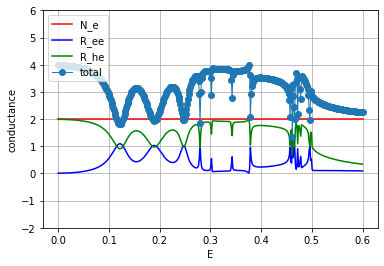

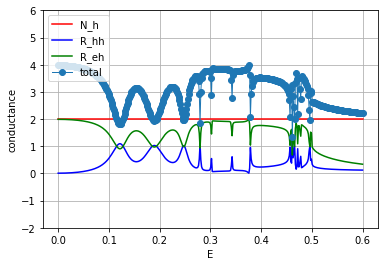

In [42]:
#Here we plot the conductance as function of energy of incident electron for zigzag MoTe2/WSe2 system
Ne = 400 #400
Emin = 0.0
Emax = 0.6


res_I = np.zeros(6)
res0 = np.zeros(Ne)
res1 = np.zeros(Ne)
res2 = np.zeros(Ne)
res3 = np.zeros(Ne)
res4 = np.zeros(Ne)
res5 = np.zeros(Ne)

Etab = np.linspace(Emin, Emax, Ne)

for i in range(Ne):
    print(i)
    res_I = andreev_conductance_3(sysf_zigzag_2, Etab[i])
    res0[i] = res_I[0]
    res1[i] = res_I[1]
    res2[i] = res_I[2]
    res3[i] = res_I[3]
    res4[i] = res_I[4]
    res5[i] = res_I[5]
    

plt.plot(np.linspace(Emin, Emax, Ne), res0, "r-", label="N_e");
plt.plot(np.linspace(Emin, Emax, Ne), res1, "b-", label="R_ee");
plt.plot(np.linspace(Emin, Emax, Ne), res2, "g-", label="R_he");
plt.plot(np.linspace(Emin, Emax, Ne), res0 - res1 + res2 , "o-", linewidth=1.0, label="total");
plt.xlabel("E")
plt.ylabel("conductance")
plt.ylim(-2,6)
plt.legend(loc="upper left")
plt.grid()
# plt.savefig("images/G(E).png")
plt.show()

plt.plot(np.linspace(Emin, Emax, Ne), res5, "r-", label="N_h");
plt.plot(np.linspace(Emin, Emax, Ne), res3, "b-", label="R_hh");
plt.plot(np.linspace(Emin, Emax, Ne), res4, "g-", label="R_eh");
plt.plot(np.linspace(Emin, Emax, Ne), res5 - res3 + res4 , "o-", linewidth=1.0, label="total");
plt.xlabel("E")
plt.ylabel("conductance")
plt.ylim(-2,6)
plt.legend(loc="upper left")
plt.grid()
# plt.savefig("images/G(E).png")
plt.show()

In [8]:
plt.figure(figsize = (12,8))
plt.plot(np.linspace(Emin, Emax, Ne), res0, "r-", label="N_e");
plt.plot(np.linspace(Emin, Emax, Ne), res1, "b-", label="R_ee");
plt.plot(np.linspace(Emin, Emax, Ne), res2, "g-", label="R_he");
plt.plot(np.linspace(Emin, Emax, Ne), res0 - res1 + res2 , "o-", linewidth=1.0, label="total");
plt.xlabel("E")
plt.ylabel("conductance")
#plt.ylim(-2,6)
plt.xlim(0.01,0.03)
plt.legend(loc="upper left")
plt.grid()
# plt.savefig("images/G(E).png")
plt.show()



NameError: name 'Emin' is not defined

<Figure size 864x576 with 0 Axes>

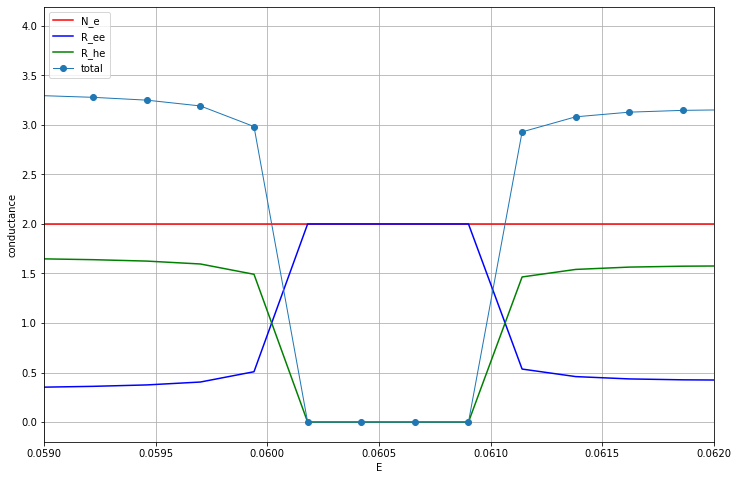

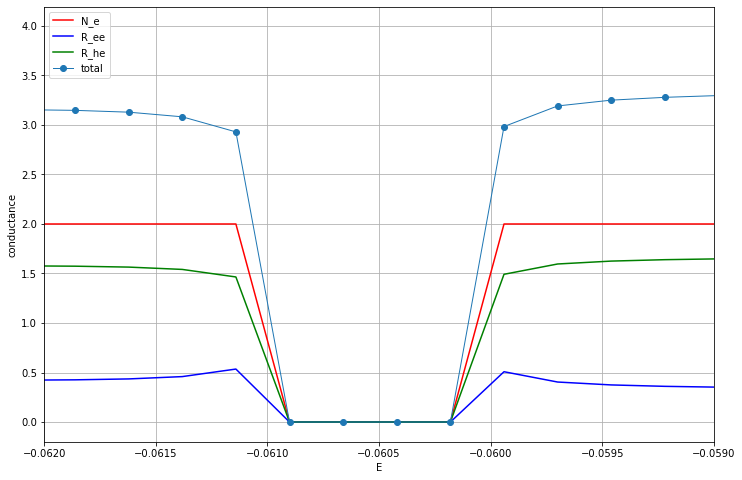

In [13]:
plt.figure(figsize = (12,8))
plt.plot(np.linspace(Emin, Emax, Ne), res0, "r-", label="N_e");
plt.plot(np.linspace(Emin, Emax, Ne), res1, "b-", label="R_ee");
plt.plot(np.linspace(Emin, Emax, Ne), res2, "g-", label="R_he");
plt.plot(np.linspace(Emin, Emax, Ne), res0 - res1 + res2 , "o-", linewidth=1.0, label="total");
plt.xlabel("E")
plt.ylabel("conductance")
#plt.ylim(-2,6)
plt.xlim(0.059,0.062)
plt.legend(loc="upper left")
plt.grid()
# plt.savefig("images/G(E).png")
plt.show()

plt.figure(figsize = (12,8))
plt.plot(np.linspace(Emin, Emax, Ne), res0, "r-", label="N_e");
plt.plot(np.linspace(Emin, Emax, Ne), res1, "b-", label="R_ee");
plt.plot(np.linspace(Emin, Emax, Ne), res2, "g-", label="R_he");
plt.plot(np.linspace(Emin, Emax, Ne), res0 - res1 + res2 , "o-", linewidth=1.0, label="total");
plt.xlabel("E")
plt.ylabel("conductance")
#plt.ylim(-2,6)
plt.xlim(-0.062, -0.059,)
plt.legend(loc="upper left")
plt.grid()
# plt.savefig("images/G(E).png")
plt.show()

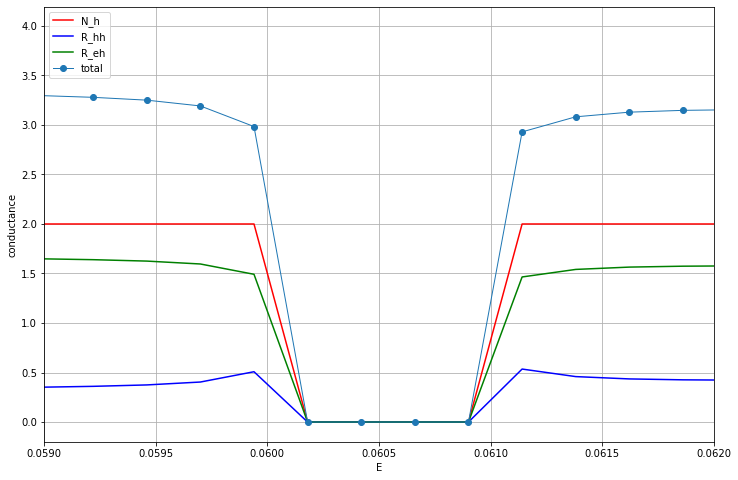

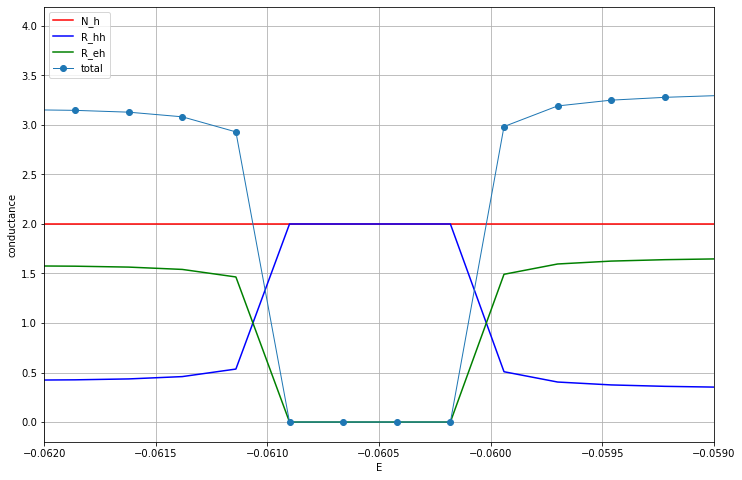

In [16]:
plt.figure(figsize = (12,8))
plt.plot(np.linspace(Emin, Emax, Ne), res5, "r-", label="N_h");
plt.plot(np.linspace(Emin, Emax, Ne), res3, "b-", label="R_hh");
plt.plot(np.linspace(Emin, Emax, Ne), res4, "g-", label="R_eh");
plt.plot(np.linspace(Emin, Emax, Ne), res5 - res3 + res4 , "o-", linewidth=1.0, label="total");
plt.xlabel("E")
plt.ylabel("conductance")
#plt.ylim(-2,6)
plt.xlim(0.059,0.062)
plt.legend(loc="upper left")
plt.grid()
# plt.savefig("images/G(E).png")
plt.show()

plt.figure(figsize = (12,8))
plt.plot(np.linspace(Emin, Emax, Ne), res5, "r-", label="N_h");
plt.plot(np.linspace(Emin, Emax, Ne), res3, "b-", label="R_hh");
plt.plot(np.linspace(Emin, Emax, Ne), res4, "g-", label="R_eh");
plt.plot(np.linspace(Emin, Emax, Ne), res5 - res3 + res4 , "o-", linewidth=1.0, label="total");
plt.xlabel("E")
plt.ylabel("conductance")
#plt.ylim(-2,6)
plt.xlim(-0.062, -0.059,)
plt.legend(loc="upper left")
plt.grid()
# plt.savefig("images/G(E).png")
plt.show()

In [14]:
mu

3.0

FileNotFoundError: [Errno 2] No such file or directory: 'images/G(E)_2.png'

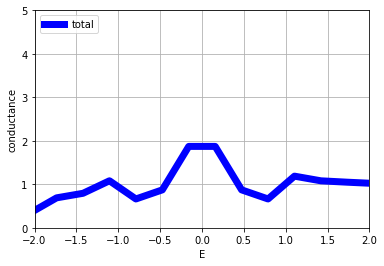

In [12]:
#Normalized chart (/N_electrons)
plt.plot(np.linspace(Emin, Emax, Ne), (res0 - res1 + res2)/res0 , "b",linewidth=7.0, label="total");
plt.xlabel("E")
plt.ylabel("conductance")
plt.ylim(0,5)
plt.xlim(-2,2)
plt.legend(loc="upper left")
plt.grid()
plt.savefig("images/G(E)_2.png")
plt.show()

In [ ]:
#Colormap mu(E)
sysf_zigzag_2 = build_graphene_system_zigzag_2()
E_min = -1.5
E_max = 1.5
Ne = 15
E_table = np.linspace(E_min, E_max, Ne)

mu_min = 2
mu_max = 5
Nmu = 15
mu_table = np.linspace(mu_min, mu_max, Nmu)

E, MU = np.meshgrid(E_table, mu_table)

G_table = np.zeros((len(mu_table), len(E_table)))   #table of conductivity

for i in range(Nmu):
    for j in range(Ne):
        e_val = E_table[j]
        mu_val = mu_table[i]
        res_I = andreev_conductance_3(sysf_zigzag_2, E_table[j], mu_table[i])
        G_table[i][j] = (res_I[0] - res_I[1] + res_I[2])/res_I[0]
        
plt.pcolormesh(E, MU, G_table, shading='auto')
plt.xlabel('E')
plt.ylabel(r'$\mu$')
plt.colorbar(label='G')
plt.savefig("images/map_2.png")

In [ ]:
#Colormap W(E)
E_min = -1.5
E_max = 1.5
Ne = 25
E_table = np.linspace(E_min, E_max, Ne)

W_min = 5
W_max = 30
Nw = 25
W_table = np.linspace(W_min, W_max, Nw)

E, W = np.meshgrid(E_table, W_table)

G_table = np.zeros((len(W_table), len(E_table)))   #table of conductivity

for i in range(Nw):
    print(i)
    for j in range(Ne):
        e_val = E_table[j]
        Wmin = -W_table[i]/2
        Wmax = W_table[i]/2
        sysf_zigzag_2 = build_graphene_system_zigzag_2(Wmin = Wmin, Wmax = Wmax)
        res_I = andreev_conductance_3(sysf_zigzag_2, E_table[j], mu = 2.5)
        num = res_I[0] - res_I[1] + res_I[2]
        den = res_I[0]

        if not np.isfinite(den) or abs(den) < 1e-10:
            G_table[i][j] = 0
        else:
            G = num / den
            if G < 0:
                G_table[i][j] = 0
            elif G > 5:
                G_table[i][j] = 3
            else:
                G_table[i][j] = G
        
plt.pcolormesh(E, W, G_table, shading='auto')
plt.xlabel('E')
plt.ylabel(r'$W$')
plt.colorbar(label='G')
plt.savefig("images/map_W_1.png")

In [6]:
#Function that creates armchair MoTe2/WSe2 system
def build_graphene_system_armchair_2(Lmin=-4, Lmax=4, Wmin=-10, Wmax=10):

    sys_gr1 = kwant.Builder()
    # Lattice
    graphene_lat = kwant.lattice.general([[np.sqrt(3)/2, -1/2], [np.sqrt(3)/2, 1/2]],  # lattice vectors
                                                    [[0,0], [1/(2*np.sqrt(3)), 1/2]], norbs=4)  # Coordinates of the sites
    lat_A, lat_B = graphene_lat.sublattices

    def ribbon(pos):
        x, y = pos
        return Lmin <= x <= Lmax and Wmin <= y <= Wmax
    
    tau_z = np.array([[1,0,0,0], [0,-1,0,0], [0,0,1,0], [0,0,0,-1]])
    zero_matrix = np.array([[0,0,0,0], [0,0,0,0], [0,0,0,0], [0,0,0,0]])

    sys_gr1 = kwant.Builder()
    
    x_cut = 0
    
    def left_half(pos):
        x, y = pos
        return (Lmin <= x <= x_cut) and (Wmin <= y <= Wmax)

    def right_half(pos):
        x, y = pos
        return (x_cut <= x <= Lmax) and (Wmin <= y <= Wmax)

    
    sys_gr1 = kwant.Builder()
    # Onsite: left (topo)
    sys_gr1[lat_A.shape(left_half, (Lmin+1, 0))] = onsite_A
    sys_gr1[lat_B.shape(left_half, (Lmin+1, 0))] = onsite_B
    # Onsite: right (SC)
    sys_gr1[lat_A.shape(right_half, (Lmax-1, 0))] = onsite_A_sup
    sys_gr1[lat_B.shape(right_half, (Lmax-1, 0))] = onsite_B_sup


    sys_gr1[kwant.builder.HoppingKind((0, 0), lat_A, lat_B)] = hop_AB
    sys_gr1[kwant.builder.HoppingKind((0, 1), lat_A, lat_B)] = hop_AB
    sys_gr1[kwant.builder.HoppingKind((-1, 1), lat_A, lat_B)] = hop_AB

    sys_gr1[kwant.builder.HoppingKind((-1, 0), lat_A, lat_A)] = hop_AA
    sys_gr1[kwant.builder.HoppingKind((0, 1), lat_A, lat_A)] = hop_AA
    sys_gr1[kwant.builder.HoppingKind((1, -1), lat_A, lat_A)] = hop_AA

    sys_gr1[kwant.builder.HoppingKind((-1, 0), lat_B, lat_B)] = hop_BB
    sys_gr1[kwant.builder.HoppingKind((0, 1), lat_B, lat_B)] = hop_BB
    sys_gr1[kwant.builder.HoppingKind((1, -1), lat_B, lat_B)] = hop_BB

    def lead0_shape(pos):
        x, y = pos
        return Wmin <= y <= Wmax

    sym = kwant.TranslationalSymmetry([-np.sqrt(3), 0])
    sym.add_site_family(graphene_lat.sublattices[0], other_vectors=[(1, -1)])
    sym.add_site_family(graphene_lat.sublattices[1], other_vectors=[(1, -1)])

    lead = kwant.Builder(sym, conservation_law=-tau_z)
    lead[lat_A.shape(lead0_shape, (0, 0))] = onsite_A 
    lead[lat_B.shape(lead0_shape, (0, 0))] = onsite_B 

    lead[kwant.builder.HoppingKind((0, 0), lat_A, lat_B)] = hopping_AB
    lead[kwant.builder.HoppingKind((0, 1), lat_A, lat_B)] = hopping_AB
    lead[kwant.builder.HoppingKind((-1, 1), lat_A, lat_B)] = hopping_AB

    lead[kwant.builder.HoppingKind((-1, 0), lat_A, lat_A)] = hopping_AA
    lead[kwant.builder.HoppingKind((0, 1), lat_A, lat_A)] = hopping_AA
    lead[kwant.builder.HoppingKind((1, -1), lat_A, lat_A)] = hopping_AA

    lead[kwant.builder.HoppingKind((-1, 0), lat_B, lat_B)] = hopping_BB
    lead[kwant.builder.HoppingKind((0, 1), lat_B, lat_B)] = hopping_BB
    lead[kwant.builder.HoppingKind((1, -1), lat_B, lat_B)] = hopping_BB
    
    lead2 = kwant.Builder(sym)

    lead2[lat_A.shape(lead0_shape, (0, 0))] = onsite_A_sup
    lead2[lat_B.shape(lead0_shape, (0, 0))] = onsite_B_sup

    #For superconductive lead we pass zeros to A-B hoppings
    lead2[kwant.builder.HoppingKind((0, 0), lat_A, lat_B)] = hopping_AB_SC   #zero_matrix#0.0*hopping_AB_0
    lead2[kwant.builder.HoppingKind((0, 1), lat_A, lat_B)] = hopping_AB_SC   #zero_matrix#0.0*hopping_AB_2  
    lead2[kwant.builder.HoppingKind((-1, 1), lat_A, lat_B)] = hopping_AB_SC  #zero_matrix#0.0*hopping_AB_1

    lead2[kwant.builder.HoppingKind((-1, 0), lat_A, lat_A)] = hopping_AA_SC
    lead2[kwant.builder.HoppingKind((0, 1), lat_A, lat_A)] = hopping_AA_SC 
    lead2[kwant.builder.HoppingKind((1, -1), lat_A, lat_A)] = hopping_AA_SC

    lead2[kwant.builder.HoppingKind((-1, 0), lat_B, lat_B)] = hopping_BB_SC 
    lead2[kwant.builder.HoppingKind((0, 1), lat_B, lat_B)] = hopping_BB_SC 
    lead2[kwant.builder.HoppingKind((1, -1), lat_B, lat_B)] = hopping_BB_SC

    sys_gr1.attach_lead(lead)
    sys_gr1.attach_lead(lead2.reversed())
    
    return sys_gr1.finalized()

In [7]:
# In this cell, we plot the bandstructure of zigzag MoTe2/WSe2 system
sysf_armchair_2 = None
def plot_wf2(Bz=0, delta= 13, t_ab=3, energy = 0.00001):
#almost all parameters are defined here. They are passed to function "build_graphene_system" and then to onsite and hopping functions
    t_aa=2
    t_bb=2
    faza = 2*np.pi/3 #AA and BB hopping phase in T, in SC phase is 0
    faza_AB = 0 #AB hoppings phase in T, in SC phase is 0
    delta_sup = 1.0
    mu = 2.5
    sign = -1 #singlet(-1), triplet(1)
    delta_sup_hopp = 0 #SC gap on AB hoppings in SC
    t_ab_cons = 2 #t_ab spin conserving hoppings in SC
    t_ab_sup = 0 # t_ab spin flip hoppings in SC 
    
    
    sysf_armchair_2 = build_graphene_system_armchair_2()
    
    
    params = dict(Bz=Bz, delta=delta, delta_sup = delta_sup, delta_sup_hopp = delta_sup_hopp, t_ab = t_ab, t_ab_sup = t_ab_sup, t_ab_cons = t_ab_cons, faza = faza, faza_AB = faza_AB, t_aa = t_aa, t_bb = t_bb, mu = mu, sign = sign)
    
    sm = kwant.smatrix(sysf_armchair_2, 0.0001, params=params)

    print("nleads:", len(sm.lead_info))
    print("lead_info:", sm.lead_info)

    for a in range(8):
        try:
            print(f"T(0,{a} <- 0,0) =", sm.transmission((0,a),(0,0)))
        except:
            break
    
    kwant.plotter.bands(sysf_armchair_2.leads[0], momenta=400, show=False, fig_size = (8,6), params= params);
    

    kwant.plotter.bands(sysf_armchair_2.leads[0], momenta=400, show=False, fig_size = (8,6), params= params);
    
    plt.ylim(-5,5)
    kwant.plotter.bands(sysf_armchair_2.leads[1], momenta=400, show=False, fig_size = (8,6), params= params);
    plt.ylim(-5,5)
    plt.grid()
    plt.show()
    
    wfs = kwant.wave_function(sysf_armchair_2, energy=energy, params= params)

    scattering_wf_0 = wfs(0)
    
    sigma_x = np.array([[0, 1],[1, 0]], dtype=complex)
    sigma_y = np.array([[0,-1j],[1j, 0]], dtype=complex)
    sigma_z = np.array([[1, 0],[0,-1 ]], dtype=complex)

    tau_x = np.array([[0, 1],[1, 0]], dtype=complex)
    tau_y = np.array([[0,-1j],[1j, 0]], dtype=complex)
    tau_z = np.array([[1, 0],[0,-1 ]], dtype=complex)

    P_el = np.array([[1,0,0,0],
                   [0,0,0,0],
                   [0,0,1,0],
                   [0,0,0,0]])
    
    P_h  = np.array([[0,0,0,0],
                   [0,1,0,0],
                   [0,0,0,0],
                   [0,0,0,1]])
    
    P_up = np.array([[1,0,0,0],
                   [0,-1,0,0],
                   [0,0,0,0],
                   [0,0,0,0]])
    
    P_down  = np.array([[0,0,0,0],
                   [0,0,0,0],
                   [0,0,1,0],
                   [0,0,0,-1]])

    Sx_bdg = 0.5 * np.kron(sigma_x, tau_z)
    Sy_bdg = 0.5 * np.kron(sigma_y, tau_z)
    Sz_bdg = 0.5 * np.kron(sigma_z, tau_z)
    
    rho_el = kwant.operator.Density(sysf_armchair_2, onsite=P_el)
    rho_h = kwant.operator.Density(sysf_armchair_2, onsite=P_h)
    rho_full = kwant.operator.Density(sysf_armchair_2, onsite=P_el-P_h)
    rho_up = kwant.operator.Density(sysf_armchair_2, onsite=P_up)
    rho_down = kwant.operator.Density(sysf_armchair_2, onsite=P_down)
    rho_sz = kwant.operator.Density(sysf_armchair_2, onsite=Sx_bdg)
    rho_sx = kwant.operator.Density(sysf_armchair_2, onsite=Sy_bdg)
    rho_sy = kwant.operator.Density(sysf_armchair_2, onsite=Sz_bdg)

    dens_el = sum(rho_el(psi) for psi in scattering_wf_0)   
    dens_h = sum(rho_h(psi) for psi in scattering_wf_0)   
    dens_full = sum(rho_full(psi) for psi in scattering_wf_0)   
    dens_up = sum(rho_up(psi) for psi in scattering_wf_0)  
    dens_down = sum(rho_down(psi) for psi in scattering_wf_0)  
    s_z = sum(rho_sz(psi) for psi in scattering_wf_0) 
    s_x = sum(rho_sx(psi) for psi in scattering_wf_0)   
    s_y = sum(rho_sy(psi) for psi in scattering_wf_0)   

    print("elektrony")
    kwant.plotter.map(sysf_armchair_2, dens_el) #,vmin=0, vmax=np.max(dens_el))
    print("dziury")
    kwant.plotter.map(sysf_armchair_2, dens_h)
    print("elektrony - dziury")
    kwant.plotter.map(sysf_armchair_2, dens_full)
    print("spin up")
    kwant.plotter.map(sysf_armchair_2, dens_up)
    print("spin down")
    kwant.plotter.map(sysf_armchair_2, dens_down)
    print("sigma_z")
    kwant.plotter.map(sysf_armchair_2, s_z, cmap="RdBu_r")
    print("sigma_x")
    kwant.plotter.map(sysf_armchair_2, s_x, cmap="RdBu_r")
    print("sigma_y")
    kwant.plotter.map(sysf_armchair_2, s_y, cmap="RdBu_r")
    
    
    J_el = kwant.operator.Current(sysf_armchair_2, onsite = P_el) #electron current
    J_h = kwant.operator.Current(sysf_armchair_2, onsite = P_h) #hole current
    J_full = kwant.operator.Current(sysf_armchair_2, onsite = P_el-P_h) # total current (electron - hole)
    J_up = kwant.operator.Current(sysf_armchair_2, onsite = P_up) #charge current carried by the spin-up sector (el_up-h_up)
    J_down = kwant.operator.Current(sysf_armchair_2, onsite = P_down) #charge current carried by the spin-down sector (el_down-h_down)
    J_sx = kwant.operator.Current(sysf_armchair_2, onsite = Sx_bdg) #Sx spin current
    J_sy = kwant.operator.Current(sysf_armchair_2, onsite = Sy_bdg) #Sy spin current
    J_sz = kwant.operator.Current(sysf_armchair_2, onsite = Sz_bdg) #Sz spin current
    current_el = sum(J_el(p, params=params) for p in scattering_wf_0)
    current_h = sum(J_h(p, params=params) for p in scattering_wf_0)
    current_full = sum(J_full(p, params=params) for p in scattering_wf_0)
    current_up = sum(J_up(p, params=params) for p in scattering_wf_0)
    current_down = sum(J_down(p, params=params) for p in scattering_wf_0)
    current_sx = sum(J_sx(p, params=params) for p in scattering_wf_0)
    current_sy = sum(J_sy(p, params=params) for p in scattering_wf_0)
    current_sz = sum(J_sz(p, params=params) for p in scattering_wf_0)
    print("Prąd elektronowy")
    kwant.plotter.current(sysf_armchair_2, current_el);
    print("Prąd dziurowy")
    kwant.plotter.current(sysf_armchair_2, current_h);
    print("Prąd całkowity (el - h)")
    kwant.plotter.current(sysf_armchair_2, current_full);
    print("Prąd o spinie up (el_up - h_up)")
    kwant.plotter.current(sysf_armchair_2, current_up);
    print("Prąd o spinie down (el_down - h_down)")
    kwant.plotter.current(sysf_armchair_2, current_down);
    print("Prąd spinowy Sz")
    kwant.plotter.current(sysf_armchair_2, current_sz);
    print("Prąd spinowy Sx")
    kwant.plotter.current(sysf_armchair_2, current_sx);
    print("Prąd spinowy Sy")
    kwant.plotter.current(sysf_armchair_2, current_sy);


interact(plot_wf2, Bz=(-10.0, 10.0), delta=(-60.0, 60.0), t_ab=(-10.0, 10.0), energy=(-2.0, 2.0));

interactive(children=(FloatSlider(value=0.0, description='Bz', max=10.0, min=-10.0), FloatSlider(value=13.0, d…

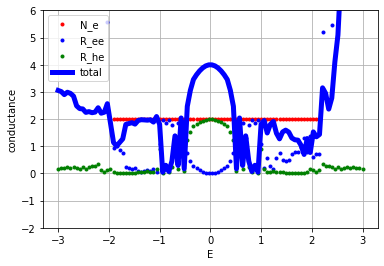

In [121]:
#Here we plot the conductance as function of energy of incident electron for zigzag MoTe2/WSe2 system

sysf_armchair_2 = build_graphene_system_armchair_2()
Ne = 100 #400
Emin = -3
Emax = 3


res_I = np.zeros(3)
res0 = np.zeros(Ne)
res1 = np.zeros(Ne)
res2 = np.zeros(Ne)

Etab = np.linspace(Emin, Emax, Ne)

for i in range(Ne):
    res_I = andreev_conductance_3(sysf_armchair_2, Etab[i], mu=2.5)
    res0[i] = res_I[0]
    res1[i] = res_I[1]
    res2[i] = res_I[2]
    

plt.plot(np.linspace(Emin, Emax, Ne), res0, "r.", label="N_e");
plt.plot(np.linspace(Emin, Emax, Ne), res1, "b.", label="R_ee");
plt.plot(np.linspace(Emin, Emax, Ne), res2, "g.", label="R_he");
plt.plot(np.linspace(Emin, Emax, Ne), res0 - res1 + res2 , "b", linewidth=5.0, label="total");
plt.xlabel("E")
plt.ylabel("conductance")
plt.ylim(-2,6)
plt.legend(loc="upper left")
plt.grid()
plt.savefig("images/G(E)_armchair.png")
plt.show()

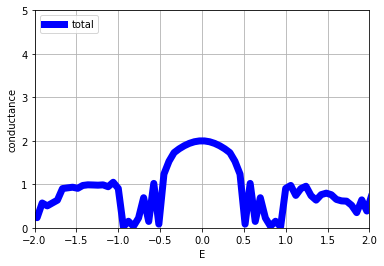

In [122]:
#Normalized chart (/N_electrons)
plt.plot(np.linspace(Emin, Emax, Ne), (res0 - res1 + res2)/res0 , "b",linewidth=7.0, label="total");
plt.xlabel("E")
plt.ylabel("conductance")
plt.ylim(0,5)
plt.xlim(-2,2)
plt.legend(loc="upper left")
plt.grid()
plt.savefig("images/G(E)_2_armchair.png")
plt.show()

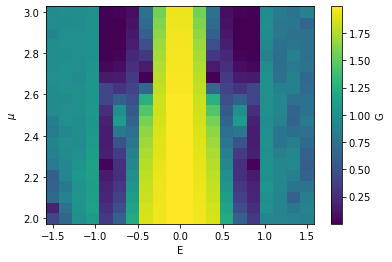

In [124]:
#Colormap mu(E)
sysf_armchair_2 = build_graphene_system_armchair_2()
E_min = -1.5
E_max = 1.5
Ne = 20
E_table = np.linspace(E_min, E_max, Ne)

mu_min = 2
mu_max = 3
Nmu = 20
mu_table = np.linspace(mu_min, mu_max, Nmu)

E, MU = np.meshgrid(E_table, mu_table)

G_table = np.zeros((len(mu_table), len(E_table)))   #table of conductivity

for i in range(Nmu):
    print(i)
    for j in range(Ne):
        e_val = E_table[j]
        mu_val = mu_table[i]
        res_I = andreev_conductance_3(sysf_armchair_2, E_table[j], mu_table[i])
        num = res_I[0] - res_I[1] + res_I[2]
        den = res_I[0]

        if not np.isfinite(den) or abs(den) < 1e-10:
            G_table[i][j] = 0
        else:
            G = num / den
            if G < 0:
                G_table[i][j] = 0
            elif G > 5:
                G_table[i][j] = 3
            else:
                G_table[i][j] = G
        
plt.pcolormesh(E, MU, G_table, shading='auto')
plt.xlabel('E')
plt.ylabel(r'$\mu$')
plt.colorbar(label='G')
plt.savefig("images/Map_amrchair_1.png")

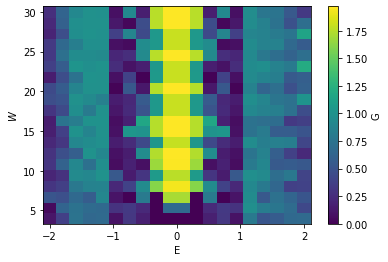

In [126]:
#Colormap W(E)
E_min = -2
E_max = 2
Ne = 20
E_table = np.linspace(E_min, E_max, Ne)

W_min = 4
W_max = 30
Nw = 20
W_table = np.linspace(W_min, W_max, Nw)

E, W = np.meshgrid(E_table, W_table)

G_table = np.zeros((len(W_table), len(E_table)))   #table of conductivity

for i in range(Nw):
    print(i)
    for j in range(Ne):
        e_val = E_table[j]
        Wmin = -W_table[i]/2
        Wmax = W_table[i]/2
        sysf_armchair_2 = build_graphene_system_armchair_2(Wmin = Wmin, Wmax = Wmax)
        res_I = andreev_conductance_3(sysf_armchair_2, E_table[j], mu = 2.5)
        num = res_I[0] - res_I[1] + res_I[2]
        den = res_I[0]

        if not np.isfinite(den) or abs(den) < 1e-10:
            G_table[i][j] = 0
        else:
            G = num / den
            if G < 0:
                G_table[i][j] = 0
            elif G > 5:
                G_table[i][j] = 3
            else:
                G_table[i][j] = G
plt.pcolormesh(E, W, G_table, shading='auto')
plt.xlabel('E')
plt.ylabel(r'$W$')
plt.colorbar(label='G')
plt.savefig("Map_armchair_2.png")